# 제10장 추가 실습 노트북

장 폴더에서 위에서 아래로 실행하세요. 프로그램 원본과 동일한 코드를 `%run`으로 실행합니다. 데이터 출처·가정·학습 범위는 각 절의 README를 함께 확인하세요. CSV는 내려받은 고정 입력이며 외부 API·GPU가 필요하지 않습니다.

In [1]:
import sys
from pathlib import Path
print("Python:", sys.version.split()[0])
print("Working folder:", Path.cwd())

Python: 3.12.14
Working folder: /workspace/scratch/52b332c0a516/textbook_repo/textbook_extensions/20261016/ch10


## 10.11 MLP 은닉층과 비선형 결정 경계

은닉 유닛 수가 비선형 결정 경계의 표현 능력에 미치는 영향을 시각화한다.

색조는 예측 확률 0.5를 기준으로 나눈 영역이다. 점은 테스트 관측이며 두 유닛·20유닛 모두 같은 훈련 분할을 쓴다.

주의: 구조 두 개를 본 뒤 선택한다면 테스트를 모델 선택에 사용한 셈이다. 이 비교는 교육용 탐색이며 확정 일반화 결론은 아니다.

In [2]:
%run sec_11_mlp_boundary.py

{
  "2": {
    "test_accuracy": 0.8555555555555555,
    "iterations": 42
  },
  "20": {
    "test_accuracy": 0.9666666666666667,
    "iterations": 147
  }
}


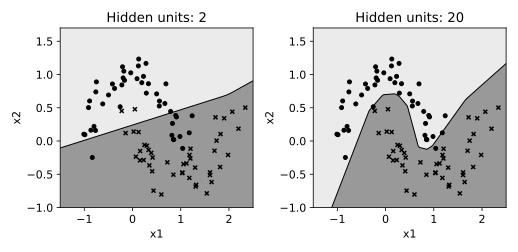

In [3]:
from IPython.display import SVG, display
display(SVG(filename="results/mlp_boundary.svg"))

### 확인 과제

은닉 유닛 수 외에 alpha와 solver를 고정한 이유를 설명하고 분류 오류 점이 경계 어디에 모이는지 확인한다.

## 10.12 훈련 크기에 따른 신경망 학습 곡선

학습 자료의 양과 훈련·검증 격차를 연결하고 epoch 손실 곡선과 구분한다.

가로축은 훈련 표본 수다. 각 점마다 새로운 모델을 훈련하므로 동일 모델의 연속 epoch를 그린 것이 아니다.

주의: 검증 표본은 고정되어 있고 단일 시드 결과다. 더 많은 자료가 언제나 단조롭게 성능을 높인다고 주장하지 않는다.

In [4]:
%run sec_12_mlp_learning_curve.py

{
  "validation_n": 54,
  "curve": [
    {
      "train_n": 18,
      "train_accuracy": 1.0,
      "validation_accuracy": 0.8888888888888888
    },
    {
      "train_n": 36,
      "train_accuracy": 1.0,
      "validation_accuracy": 0.9074074074074074
    },
    {
      "train_n": 60,
      "train_accuracy": 1.0,
      "validation_accuracy": 0.9629629629629629
    },
    {
      "train_n": 90,
      "train_accuracy": 1.0,
      "validation_accuracy": 0.9814814814814815
    },
    {
      "train_n": 124,
      "train_accuracy": 1.0,
      "validation_accuracy": 0.9814814814814815
    }
  ]
}


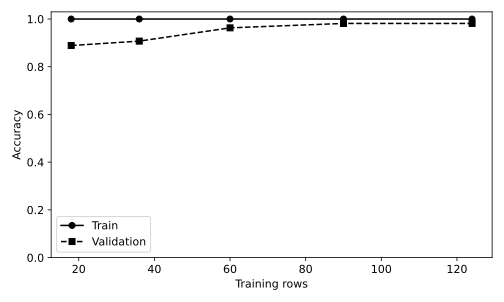

In [5]:
from IPython.display import SVG, display
display(SVG(filename="results/mlp_learning_curve.svg"))

### 확인 과제

작은 표본에서도 모든 클래스가 포함되는지 확인하고, 학습 곡선에 여러 시드의 변동 폭을 추가할 방법을 제안한다.